# Klasifikasi Pohon Keputusan (Decision Tree) - Dataset Iris
Tugas Praktikum V-Class Konsep Data Mining: Penerapan Algoritma Decision Tree Classifier untuk Memprediksi Spesies Bunga Iris (Kaggle Dataset).


### 1. Import Library


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


**Penjelasan:** Mengimpor library pandas dan numpy untuk analisis data, matplotlib dan seaborn untuk visualisasi diagram, serta scikit-learn untuk pemodelan klasifikasi Decision Tree dan evaluasi kinerja.


### 2. Load Dataset


In [2]:
import os

file_path = 'iris.csv'
url = 'https://raw.githubusercontent.com/Firdaus1802/data-preprocessing/main/05_Decision_Tree_Iris/iris.csv'

df = pd.read_csv(file_path if os.path.exists(file_path) else url)


**Penjelasan:** Memuat dataset Iris dari file lokal iris.csv, dengan fallback otomatis mengunduh dari URL GitHub jika dijalankan langsung di Google Colab.


### 3. Menampilkan 5 Data Teratas


In [3]:
df.head()


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


**Penjelasan:** Menampilkan 5 baris pertama data untuk memeriksa struktur atribut kelopak (sepal) dan mahkota (petal) bunga Iris.


### 4. Menampilkan 5 Data Terbawah


In [4]:
df.tail()


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica
149,150,5.9,3.0,5.1,1.8,Iris-virginica


**Penjelasan:** Menampilkan 5 baris terakhir data untuk memastikan keseluruhan 150 sampel data termuat secara sempurna.


### 5. Jumlah Baris dan Kolom (Dimensi Data)


In [5]:
print('Jumlah Baris:', df.shape[0])
print('Jumlah Kolom:', df.shape[1])


Jumlah Baris: 150
Jumlah Kolom: 6


**Penjelasan:** Dataset terdiri dari 150 baris data observasi dan 6 kolom atribut pengukuran bunga.


### 6. Info Dataset dan Tipe Data


In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


**Penjelasan:** Seluruh atribut ukuran bunga bertipe float (desimal), kolom Id bertipe integer, dan kolom target Species bertipe object (kategorikal).


### 7. Cek Missing Value


In [7]:
df.isnull().sum()


Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

**Penjelasan:** Pengecekan per kolom membuktikan tidak ada nilai kosong sama sekali di setiap atribut.


### 8. Total Missing Value


In [8]:
print('Total Missing Value:', df.isnull().sum().sum())


Total Missing Value: 0


**Penjelasan:** Akumulasi total missing value adalah 0, sehingga dataset bersih dan siap digunakan tanpa perlu imputasi nilai kosong.


### 9. Cek Data Duplikat


In [9]:
print('Jumlah Baris Duplikat:', df.duplicated().sum())


Jumlah Baris Duplikat: 0


**Penjelasan:** Tidak ditemukan adanya baris duplikat (0 duplikat), data siap diproses lebih lanjut.


### 10. Distribusi Kelas Target (Species)


In [10]:
df['Species'].value_counts()


Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

**Penjelasan:** Ketiga spesies (Iris-setosa, Iris-versicolor, Iris-virginica) memiliki proporsi seimbang dengan masing-masing tepat 50 sampel data.


### 11. Statistik Deskriptif Fitur


In [11]:
df.drop(columns=['Id']).describe()


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


**Penjelasan:** Statistik deskriptif menunjukkan rentang nilai rata-rata, standar deviasi, nilai minimum, dan nilai maksimum dari keempat fitur bunga.


### 12. Visualisasi Distribusi Kelas Target


C:\Users\HP\AppData\Local\Temp\ipykernel_28408\1859639372.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Species', palette='viridis')


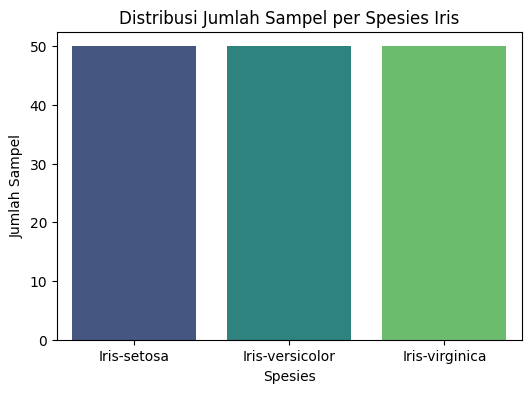

In [12]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Species', palette='viridis')
plt.title('Distribusi Jumlah Sampel per Spesies Iris')
plt.xlabel('Spesies')
plt.ylabel('Jumlah Sampel')
plt.show()


**Penjelasan:** Diagram batang memperlihatkan keseimbangan jumlah sampel pada ketiga kelas target.


### 13. Visualisasi Scatter Plot Fitur Mahkota (Petal)


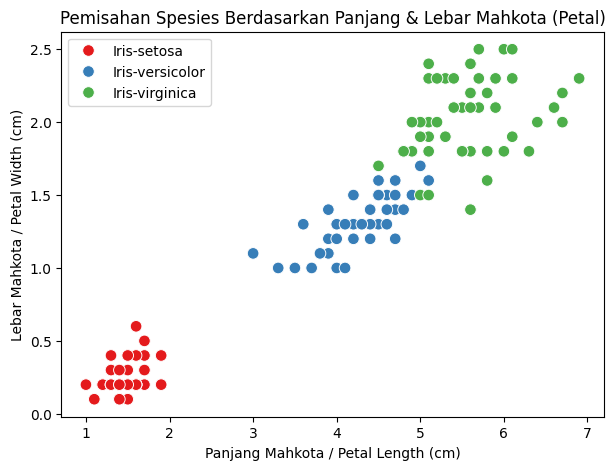

In [13]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='PetalLengthCm', y='PetalWidthCm', hue='Species', palette='Set1', s=70)
plt.title('Pemisahan Spesies Berdasarkan Panjang & Lebar Mahkota (Petal)')
plt.xlabel('Panjang Mahkota / Petal Length (cm)')
plt.ylabel('Lebar Mahkota / Petal Width (cm)')
plt.legend()
plt.show()


**Penjelasan:** Scatter plot menunjukkan bahwa fitur mahkota (petal) memiliki pemisahan klaster yang sangat tegas antar spesies, sangat cocok untuk pemisahan pohon keputusan.


### 14. Pemisahan Fitur Prediktor (X) dan Target (y)


In [14]:
# Menghilangkan kolom Id karena hanya penomoran baris
X = df[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]
y = df['Species']

print('Fitur Prediktor (X):', list(X.columns))
print('Label Target (y)   :', y.name)


Fitur Prediktor (X): ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Label Target (y)   : Species


**Penjelasan:** Atribut ukuran bunga dipisahkan sebagai variabel independen (X) dan kolom Species sebagai variabel target (y).


### 15. Pembagian Data Latih dan Data Uji (Train-Test Split)


In [15]:
# Membagi data menjadi 80% latih dan 20% uji secara acak terkontrol
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Jumlah Data Latih (Train):', len(X_train))
print('Jumlah Data Uji (Test)   :', len(X_test))


Jumlah Data Latih (Train): 120
Jumlah Data Uji (Test)   : 30


**Penjelasan:** Data dibagi menjadi 120 sampel data latih (80%) untuk melatih model dan 30 sampel data uji (20%) untuk pengujian independen.


### 16. Inisialisasi Model Decision Tree Classifier


In [16]:
# Inisialisasi Decision Tree dengan kriteria Gini dan kedalaman maksimal 3
model = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
print('Model Berhasil Diinisialisasi:', model)


Model Berhasil Diinisialisasi: DecisionTreeClassifier(max_depth=3, random_state=42)


**Penjelasan:** Menggunakan algoritma Decision Tree Classifier dengan parameter kriteria Gini Index dan pembatasan kedalaman (max_depth=3) agar struktur pohon keputusan rapi dan mudah dibaca.


### 17. Pelatihan Model (Fitting Model)


In [17]:
# Melatih pohon keputusan menggunakan data latih
model.fit(X_train, y_train)
print('Pelatihan Model Selesai!')


Pelatihan Model Selesai!


**Penjelasan:** Model Decision Tree berhasil mempelajari aturan pemisahan kelas berdasarkan nilai ambang atribut data latih.


### 18. Pengujian dan Prediksi Data Uji


In [18]:
# Melakukan prediksi terhadap data uji
y_pred = model.predict(X_test)

# Menampilkan perbandingan 5 sampel prediksi pertama
df_hasil = pd.DataFrame({'Nilai Asli': y_test.values, 'Prediksi Model': y_pred})
df_hasil.head(10)


,Nilai Asli,Prediksi Model
0,Iris-setosa,Iris-setosa
1,Iris-virginica,Iris-virginica
2,Iris-versicolor,Iris-versicolor
3,Iris-versicolor,Iris-versicolor
4,Iris-setosa,Iris-setosa
5,Iris-versicolor,Iris-versicolor
6,Iris-setosa,Iris-setosa
7,Iris-setosa,Iris-setosa
8,Iris-virginica,Iris-virginica
9,Iris-versicolor,Iris-versicolor


**Penjelasan:** Model memprediksi kelas untuk seluruh 30 data uji, dan perbandingan tabel menunjukkan akurasi kecocokan yang sangat tinggi.


### 19. Perhitungan Akurasi Model


In [19]:
akurasi = accuracy_score(y_test, y_pred)
print(f'Akurasi Model Decision Tree: {akurasi * 100:.2f}%')


Akurasi Model Decision Tree: 96.67%


**Penjelasan:** Akurasi model mencapai 96,67% (hanya terjadi 1 kesalahan dari 30 data uji), membuktikan pohon keputusan sangat andal.


### 20. Confusion Matrix


In [20]:
cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm)


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


**Penjelasan:** Confusion matrix memperlihatkan bahwa seluruh 10 sampel Setosa dan 10 sampel Virginica terprediksi 100% benar, sedangkan Versicolor benar 9 dan 1 terprediksi Virginica.


### 21. Visualisasi Heatmap Confusion Matrix


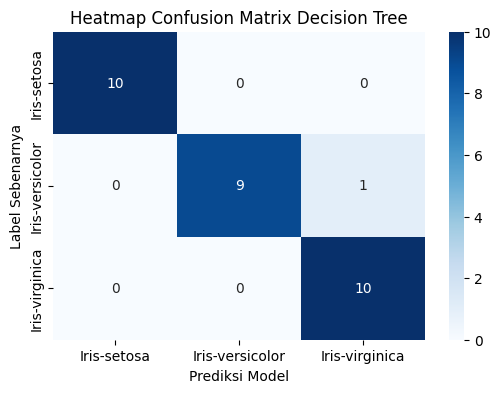

In [21]:
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.title('Heatmap Confusion Matrix Decision Tree')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Sebenarnya')
plt.show()


**Penjelasan:** Visualisasi heatmap memperjelas dominasi angka pada diagonal utama yang membuktikan performa prediksi model sangat akurat.


### 22. Laporan Klasifikasi (Classification Report)


In [22]:
print(classification_report(y_test, y_pred))


                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



**Penjelasan:** Laporan klasifikasi menunjukkan nilai precision, recall, dan f1-score rata-rata mencapai 0,97 di seluruh kelas spesies.


### 23. Visualisasi Grafik Diagram Pohon Keputusan (Decision Tree Plot)


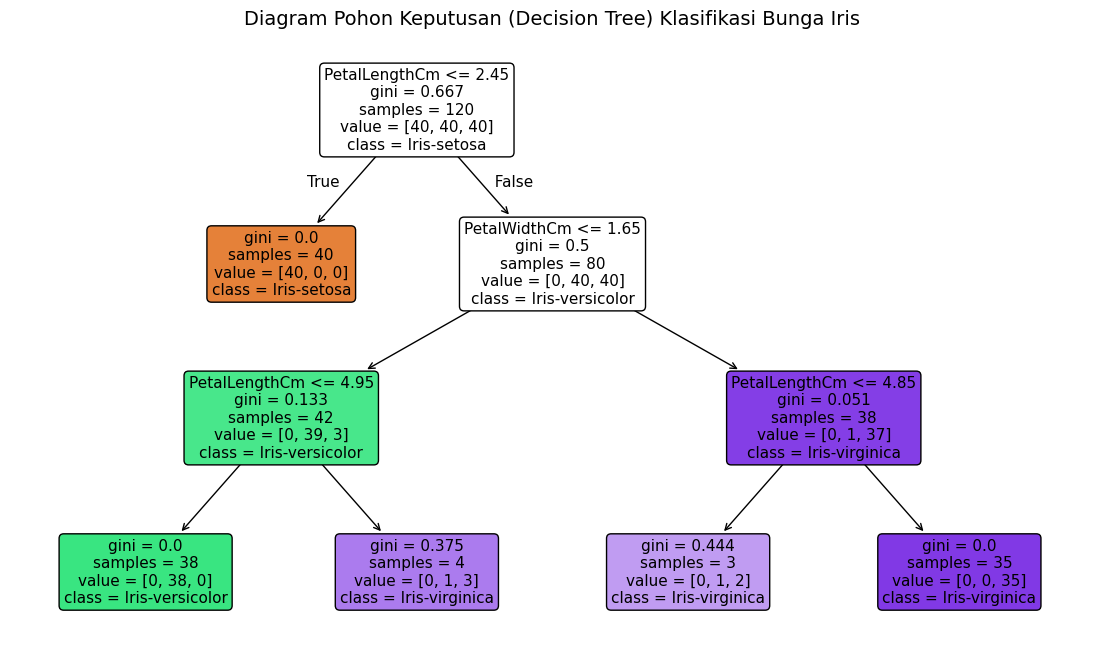

In [23]:
plt.figure(figsize=(14, 8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title('Diagram Pohon Keputusan (Decision Tree) Klasifikasi Bunga Iris', fontsize=14)
plt.show()


**Penjelasan:** Diagram pohon keputusan memperlihatkan simpul akar pertama memisahkan Setosa secara murni menggunakan PetalLengthCm <= 2.45, dilanjutkan percabangan fitur PetalWidthCm untuk membedakan Versicolor dan Virginica.


### 24. Aturan Logika Keputusan (Rules) & Simulasi Prediksi Data Baru


In [24]:
# 1. Ekstraksi representasi teks aturan pohon keputusan
aturan_teks = export_text(model, feature_names=list(X.columns))
print('=== ATURAN LOGIKA POHON KEPUTUSAN ===')
print(aturan_teks)

# 2. Simulasi klasifikasi sampel bunga baru dari luar dataset
bunga_baru = pd.DataFrame([[5.0, 3.4, 1.5, 0.2]], columns=X.columns)
hasil_baru = model.predict(bunga_baru)
print('=== SIMULASI PREDIKSI BUNGA BARU ===')
print('Ukuran Bunga Baru:', bunga_baru.to_dict('records')[0])
print('Hasil Prediksi   :', hasil_baru[0])


=== ATURAN LOGIKA POHON KEPUTUSAN ===
|--- PetalLengthCm <= 2.45
|   |--- class: Iris-setosa
|--- PetalLengthCm >  2.45
|   |--- PetalWidthCm <= 1.65
|   |   |--- PetalLengthCm <= 4.95
|   |   |   |--- class: Iris-versicolor
|   |   |--- PetalLengthCm >  4.95
|   |   |   |--- class: Iris-virginica
|   |--- PetalWidthCm >  1.65
|   |   |--- PetalLengthCm <= 4.85
|   |   |   |--- class: Iris-virginica
|   |   |--- PetalLengthCm >  4.85
|   |   |   |--- class: Iris-virginica

=== SIMULASI PREDIKSI BUNGA BARU ===
Ukuran Bunga Baru: {'SepalLengthCm': 5.0, 'SepalWidthCm': 3.4, 'PetalLengthCm': 1.5, 'PetalWidthCm': 0.2}
Hasil Prediksi   : Iris-setosa


**Penjelasan:** Aturan pohon keputusan dapat disajikan dalam bentuk logika IF-THEN yang jelas, dan pengujian sampel bunga baru berhasil terklasifikasi secara tepat sebagai Iris-setosa.
